# Water Pump — Parallel Hybrid Model (First Principles + ML Residual Correction)

**Objective:** Predict **Pump Brake Power** using a first-principles physics baseline, then correct it with an ML model that learns the residual error.

| Role | Variables |
|------|-----------|
| Inputs | Water Flow, Inlet Pressure, Outlet Pressure, Water Density |
| Output | Pump Brake Power (kW) |

**Hybrid chain**
1. **First Principles** → `P_phys = P_hyd / eta_bar`
2. **Residual target** → `e = P_actual − P_phys`
3. **ML Residual Correction** → `ê = LinearRegression(Q, Pin, Pout, ρ)`
4. **Hybrid** → `P_hybrid = P_phys + ê`

## 1. Imports

In [2]:
import numpy as np  # numerical operations
import pandas as pd  # data manipulation
import joblib  # save/load ML models
import matplotlib.pyplot as plt  # plotting

from sklearn.linear_model import LinearRegression  # residual correction model
from sklearn.model_selection import train_test_split  # train/test split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # metrics

pd.set_option("display.max_columns", 20)
plt.style.use("seaborn-v0_8-whitegrid")

## 2. Load & clean data

In [3]:
# Load data from Excel file
df_raw = pd.read_excel("PumpData_0.005.xlsx")
print("Raw shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
df_raw.head()

# Drop first row (unit labels), convert all columns to numeric
df = df_raw.iloc[1:].copy()
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing values
df = df.dropna().reset_index(drop=True)

print("After numeric clean:", df.shape)
print("Nulls:")
print(df.isnull().sum())
df.describe().T

# Remove rows with non-physical (<=0) brake power values
n_bad = (df["Pump Brake power"] <= 0).sum()
print(f"Rows with Brake Power <= 0: {n_bad}")

df = df[df["Pump Brake power"] > 0].copy().reset_index(drop=True)
print("Clean shape:", df.shape)
df.head()

Raw shape: (313, 6)
Columns: ['Water Flow', 'Water inlet Pressure', 'Water outlet pressure', 'Water Density', 'Pump Brake power', 'Pump efficiency']
After numeric clean: (312, 6)
Nulls:
Water Flow               0
Water inlet Pressure     0
Water outlet pressure    0
Water Density            0
Pump Brake power         0
Pump efficiency          0
dtype: int64
Rows with Brake Power <= 0: 2
Clean shape: (310, 6)


,Water Flow,Water inlet Pressure,Water outlet pressure,Water Density,Pump Brake power,Pump efficiency
0,500,6.013,25,999.9,0.6113,75
1,500,6.013,50,999.9,1.4160,75
2,500,6.013,75,999.9,2.2210,75
3,500,6.013,100,999.9,3.0260,75
4,500,6.013,125,999.9,3.8310,75


## 3. Physics features — Hydraulic Power

Assumed units:
- Water Flow → **kg/h**
- Pressures → **bar**
- Density → **kg/m³**
- Brake Power → **kW**

`P_hyd (kW) = Q(m³/s) * ΔP(Pa) / 1000`

In [4]:
def compute_hydraulic_power(water_flow, inlet_pressure, outlet_pressure, water_density):
    """First-principles helper: hydraulic power in kW."""
    mass_flow_kgs = water_flow / 3600.0
    volumetric_flow_m3s = mass_flow_kgs / water_density
    delta_p_pa = (outlet_pressure - inlet_pressure) * 100_000.0
    return (volumetric_flow_m3s * delta_p_pa) / 1000.0

df["Mass Flow (kg/s)"] = df["Water Flow"] / 3600.0
df["Volumetric Flow (m3/s)"] = df["Mass Flow (kg/s)"] / df["Water Density"]
df["Delta P (bar)"] = df["Water outlet pressure"] - df["Water inlet Pressure"]
df["Delta P (Pa)"] = df["Delta P (bar)"] * 100_000.0
df["Hydraulic Power (kW)"] = (df["Volumetric Flow (m3/s)"] * df["Delta P (Pa)"]) / 1000.0

df[["Water Flow", "Delta P (bar)", "Hydraulic Power (kW)", "Pump Brake power"]].head(10)

,Water Flow,Delta P (bar),Hydraulic Power (kW),Pump Brake power
0,500,18.987,0.263735,0.6113
1,500,43.987,0.610992,1.4160
2,500,68.987,0.958249,2.2210
3,500,93.987,1.305506,3.0260
4,500,118.987,1.652762,3.8310
5,500,143.987,2.000019,4.6360
6,500,168.987,2.347276,5.4410
7,500,193.987,2.694533,6.2460
8,500,218.987,3.041790,7.0500
9,500,243.987,3.389047,7.8550


## 4. Train / test split

In [5]:
FEATURE_COLS = [
    "Water Flow",
    "Water inlet Pressure",
    "Water outlet pressure",
    "Water Density",
]
TARGET_COL = "Pump Brake power"

train_df, test_df = train_test_split(df, test_size=0.20, random_state=42)

X_train = train_df[FEATURE_COLS].copy()
y_train = train_df[TARGET_COL].copy()
X_test = test_df[FEATURE_COLS].copy()
y_test = test_df[TARGET_COL].copy()

print("Train samples:", len(train_df))
print("Test  samples:", len(test_df))
print("ML residual features:", FEATURE_COLS)

Train samples: 248
Test  samples: 62
ML residual features: ['Water Flow', 'Water inlet Pressure', 'Water outlet pressure', 'Water Density']


## 5. First Principles — Physics baseline

Mean observed efficiency from **training data only**:

`eta_bar = mean(P_hyd / P_brake)_train`

`P_phys = P_hyd / eta_bar`

In [6]:
# Sample efficiency on training rows only
train_efficiency = train_df["Hydraulic Power (kW)"] / train_df["Pump Brake power"]
physics_efficiency = train_efficiency.mean()

print(f"Physics efficiency (train mean): {physics_efficiency:.6f}")
print(train_efficiency.describe())

def physics_brake_power(hydraulic_power_kw, eta=physics_efficiency):
    return hydraulic_power_kw / eta

train_df = train_df.copy()
test_df = test_df.copy()

train_df["Physics Brake Power"] = physics_brake_power(train_df["Hydraulic Power (kW)"])
test_df["Physics Brake Power"] = physics_brake_power(test_df["Hydraulic Power (kW)"])

train_df[["Hydraulic Power (kW)", "Physics Brake Power", "Pump Brake power"]].head()

Physics efficiency (train mean): 0.431424
count    248.000000
mean       0.431424
std        0.000061
min        0.431255
25%        0.431392
50%        0.431427
75%        0.431460
max        0.431607
dtype: float64


,Hydraulic Power (kW),Physics Brake Power,Pump Brake power
126,56.585200,131.159257,131.2
109,18.206723,42.201500,42.2
247,138.950937,322.075411,322.1
234,118.629821,274.972946,275.0
202,134.757517,312.355453,312.4


## 6. Residual target

Physics error on each sample:

`e = P_actual − P_phys`

The ML model learns to predict this residual from operating inputs.

In [7]:
train_df["Residual (Actual - Physics)"] = (
    train_df["Pump Brake power"] - train_df["Physics Brake Power"]
)
test_df["Residual (Actual - Physics)"] = (
    test_df["Pump Brake power"] - test_df["Physics Brake Power"]
)

y_residual_train = train_df["Residual (Actual - Physics)"]
y_residual_test = test_df["Residual (Actual - Physics)"]

print("Train residual stats")
print(y_residual_train.describe())
print()
print("Test residual stats")
print(y_residual_test.describe())

Train residual stats
count    248.000000
mean       0.000778
std        0.021181
min       -0.053085
25%       -0.004548
50%       -0.000186
75%        0.006624
max        0.045541
Name: Residual (Actual - Physics), dtype: float64

Test residual stats
count    62.000000
mean     -0.001406
std       0.019467
min      -0.053419
25%      -0.005316
50%      -0.000275
75%       0.002919
max       0.040043
Name: Residual (Actual - Physics), dtype: float64


## 7. ML Residual Correction — Linear Regression

ML predicts the physics residual (can be positive or negative), not brake power directly.

**Model:** `LinearRegression()` — residuals are signed, so coefficients are unconstrained.

`P_hybrid = P_phys + ê`

In [8]:
# Train linear regression to predict physics residual
residual_model = LinearRegression()
residual_model.fit(X_train, y_residual_train)

print("Residual ML coefficients")
print("------------------------")
for name, coef in zip(FEATURE_COLS, residual_model.coef_):
    print(f"{name:28s}: {coef:.6e}")
print(f"{'Intercept':28s}: {residual_model.intercept_:.6f}")

# Predicted residual and hybrid brake power
train_df["Predicted Residual"] = residual_model.predict(X_train)
test_df["Predicted Residual"] = residual_model.predict(X_test)

train_df["Hybrid Brake Power"] = (
    train_df["Physics Brake Power"] + train_df["Predicted Residual"]
)
test_df["Hybrid Brake Power"] = (
    test_df["Physics Brake Power"] + test_df["Predicted Residual"]
)

train_df[
    [
        "Physics Brake Power",
        "Residual (Actual - Physics)",
        "Predicted Residual",
        "Hybrid Brake Power",
        "Pump Brake power",
    ]
].head()

Residual ML coefficients
------------------------
Water Flow                  : -5.412915e-08
Water inlet Pressure        : 0.000000e+00
Water outlet pressure       : 7.423230e-06
Water Density               : -1.887559e-35
Intercept                   : 0.000252


,Physics Brake Power,Residual (Actual - Physics),Predicted Residual,Hybrid Brake Power,Pump Brake power
126,131.159257,0.040743,0.001168,131.160425,131.2
109,42.201500,-0.001500,0.000295,42.201795,42.2
247,322.075411,0.024589,0.000998,322.076409,322.1
234,274.972946,0.027054,0.000867,274.973813,275.0
202,312.355453,0.044547,0.001586,312.357039,312.4


## 8. Evaluation

In [9]:
def report_metrics(name, y_true, y_pred, unit="kW"):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"{name}")
    print("-" * len(name))
    print(f"MAE  : {mae:.6f} {unit}")
    print(f"RMSE : {rmse:.6f} {unit}")
    print(f"R2   : {r2:.6f}")
    print(f"MAPE : {mape:.4f} %")
    print()
    return {"MAE": mae, "RMSE": rmse, "R2": r2, "MAPE": mape}

print("TRAIN SET")
print("=========")
report_metrics("Physics", train_df["Pump Brake power"], train_df["Physics Brake Power"])
report_metrics("Hybrid ", train_df["Pump Brake power"], train_df["Hybrid Brake Power"])
report_metrics(
    "Residual ML (target = e)",
    train_df["Residual (Actual - Physics)"],
    train_df["Predicted Residual"],
)

print("TEST SET")
print("========")
report_metrics("Physics", test_df["Pump Brake power"], test_df["Physics Brake Power"])
report_metrics("Hybrid ", test_df["Pump Brake power"], test_df["Hybrid Brake Power"])
report_metrics(
    "Residual ML (target = e)",
    test_df["Residual (Actual - Physics)"],
    test_df["Predicted Residual"],
)

TRAIN SET
Physics
-------
MAE  : 0.014540 kW
RMSE : 0.021152 kW
R2   : 1.000000
MAPE : 0.0107 %

Hybrid 
-------
MAE  : 0.014608 kW
RMSE : 0.021125 kW
R2   : 1.000000
MAPE : 0.0121 %

Residual ML (target = e)
------------------------
MAE  : 0.014608 kW
RMSE : 0.021125 kW
R2   : 0.001251
MAPE : 200.0104 %

TEST SET
Physics
-------
MAE  : 0.012639 kW
RMSE : 0.019361 kW
R2   : 1.000000
MAPE : 0.0108 %

Hybrid 
-------
MAE  : 0.012826 kW
RMSE : 0.019565 kW
R2   : 1.000000
MAPE : 0.0127 %

Residual ML (target = e)
------------------------
MAE  : 0.012826 kW
RMSE : 0.019565 kW
R2   : -0.026607
MAPE : 923.7291 %



{'MAE': 0.012826314682067507,
 'RMSE': np.float64(0.019564827527430922),
 'R2': -0.026606541161961816,
 'MAPE': np.float64(923.729108931159)}

## 9. Plots

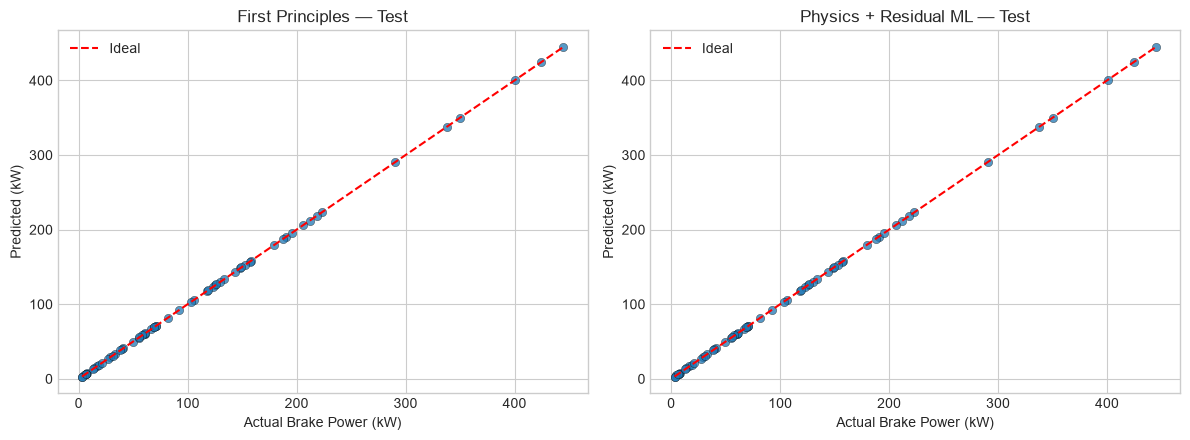

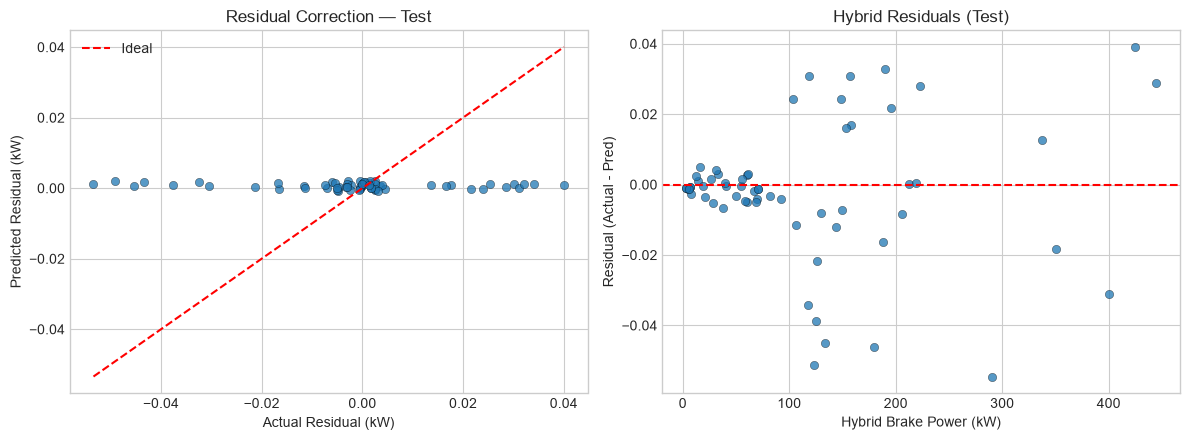

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

comparisons = [
    ("Physics Brake Power", "First Principles"),
    ("Hybrid Brake Power", "Physics + Residual ML"),
]

for ax, (col, title) in zip(axes, comparisons):
    ax.scatter(
        test_df["Pump Brake power"], test_df[col],
        alpha=0.75, edgecolor="k", linewidth=0.3
    )
    lims = [
        min(test_df["Pump Brake power"].min(), test_df[col].min()),
        max(test_df["Pump Brake power"].max(), test_df[col].max()),
    ]
    ax.plot(lims, lims, "r--", label="Ideal")
    ax.set_xlabel("Actual Brake Power (kW)")
    ax.set_ylabel("Predicted (kW)")
    ax.set_title(f"{title} — Test")
    ax.legend()

plt.tight_layout()
plt.show()

# Residual: actual physics error vs ML-predicted residual
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(
    test_df["Residual (Actual - Physics)"],
    test_df["Predicted Residual"],
    alpha=0.75, edgecolor="k", linewidth=0.3
)
rlims = [
    min(test_df["Residual (Actual - Physics)"].min(), test_df["Predicted Residual"].min()),
    max(test_df["Residual (Actual - Physics)"].max(), test_df["Predicted Residual"].max()),
]
axes[0].plot(rlims, rlims, "r--", label="Ideal")
axes[0].set_xlabel("Actual Residual (kW)")
axes[0].set_ylabel("Predicted Residual (kW)")
axes[0].set_title("Residual Correction — Test")
axes[0].legend()

hybrid_residual = test_df["Pump Brake power"] - test_df["Hybrid Brake Power"]
axes[1].scatter(
    test_df["Hybrid Brake Power"], hybrid_residual,
    alpha=0.75, edgecolor="k", linewidth=0.3
)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Hybrid Brake Power (kW)")
axes[1].set_ylabel("Residual (Actual - Pred)")
axes[1].set_title("Hybrid Residuals (Test)")

plt.tight_layout()
plt.show()

### Feature importance (residual ML)

Permutation importance on the **test set**: how much residual MAE rises if a feature is shuffled.

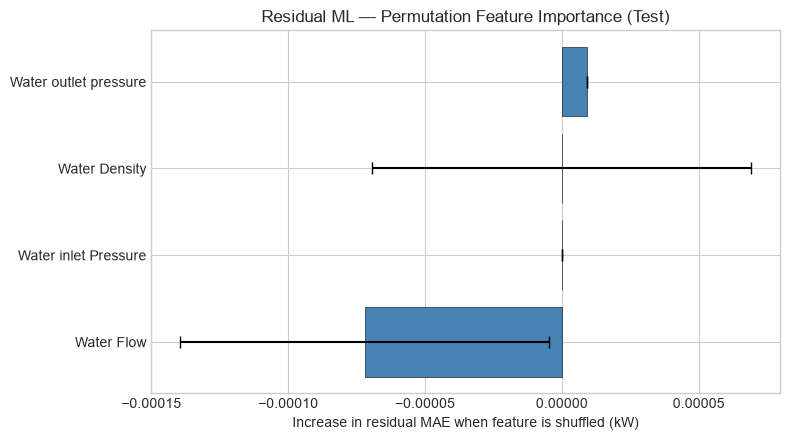

Permutation importance (mean residual MAE increase)
Water outlet pressure    0.000009
Water inlet Pressure     0.000000
Water Density            0.000000
Water Flow              -0.000072


In [11]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    residual_model,
    X_test,
    y_residual_test,
    n_repeats=30,
    random_state=42,
    scoring="neg_mean_absolute_error",
)

importance = pd.Series(perm.importances_mean, index=FEATURE_COLS).sort_values()
importance_std = pd.Series(perm.importances_std, index=importance.index)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(
    importance.index,
    importance.values,
    xerr=importance_std.values,
    color="steelblue",
    edgecolor="k",
    linewidth=0.4,
    capsize=4,
)
ax.set_xlabel("Increase in residual MAE when feature is shuffled (kW)")
ax.set_title("Residual ML — Permutation Feature Importance (Test)")
plt.tight_layout()
plt.show()

print("Permutation importance (mean residual MAE increase)")
print(importance.sort_values(ascending=False).to_string())

## 10. Inference function + demo

In [12]:
def residual_hybrid_predict(
    water_flow,
    inlet_pressure,
    outlet_pressure,
    water_density,
    model=residual_model,
    eta=physics_efficiency,
):
    """
    Parallel Hybrid — First Principles + ML Residual Correction

    First Principles : P_phys = P_hyd / eta
    ML Residual      : ê = LinearRegression(Q, Pin, Pout, rho)
    Hybrid           : P_hybrid = P_phys + ê
    """
    if water_flow <= 0:
        raise ValueError("Water Flow must be > 0.")
    if water_density <= 0:
        raise ValueError("Water Density must be > 0.")
    if outlet_pressure <= inlet_pressure:
        raise ValueError("Outlet pressure must be greater than inlet pressure.")
    if eta <= 0:
        raise ValueError("Physics efficiency must be > 0.")

    hydraulic_power_kw = compute_hydraulic_power(
        water_flow, inlet_pressure, outlet_pressure, water_density
    )
    p_phys = hydraulic_power_kw / eta

    model_input = pd.DataFrame({
        "Water Flow": [water_flow],
        "Water inlet Pressure": [inlet_pressure],
        "Water outlet pressure": [outlet_pressure],
        "Water Density": [water_density],
    })
    e_hat = float(model.predict(model_input)[0])
    p_hybrid = p_phys + e_hat

    return {
        "Hydraulic Power (kW)": hydraulic_power_kw,
        "Physics Brake Power (kW)": p_phys,
        "Predicted Residual (kW)": e_hat,
        "Hybrid Brake Power (kW)": p_hybrid,
        "Physics Efficiency": eta,
    }

In [13]:
# Demo on first cleaned sample
sample = df.iloc[0]

result = residual_hybrid_predict(
    water_flow=sample["Water Flow"],
    inlet_pressure=sample["Water inlet Pressure"],
    outlet_pressure=sample["Water outlet pressure"],
    water_density=sample["Water Density"],
)

print("DEMO OPERATING POINT")
print("--------------------")
print(f"Water Flow           : {sample['Water Flow']:.1f} kg/h")
print(f"Inlet Pressure       : {sample['Water inlet Pressure']:.3f} bar")
print(f"Outlet Pressure      : {sample['Water outlet pressure']:.3f} bar")
print(f"Water Density        : {sample['Water Density']:.1f} kg/m3")
print()

print("RESIDUAL HYBRID OUTPUT")
print("----------------------")
for k, v in result.items():
    if isinstance(v, float):
        print(f"{k:28s}: {v:.6f}")
    else:
        print(f"{k:28s}: {v}")

print(f"{'Actual Brake Power (kW)':28s}: {sample['Pump Brake power']:.6f}")

DEMO OPERATING POINT
--------------------
Water Flow           : 500.0 kg/h
Inlet Pressure       : 6.013 bar
Outlet Pressure      : 25.000 bar
Water Density        : 999.9 kg/m3

RESIDUAL HYBRID OUTPUT
----------------------
Hydraulic Power (kW)        : 0.263735
Physics Brake Power (kW)    : 0.611313
Predicted Residual (kW)     : 0.000411
Hybrid Brake Power (kW)     : 0.611723
Physics Efficiency          : 0.431424
Actual Brake Power (kW)     : 0.611300
